# Financial Sentiment Analysis: FinBERT vs a Keyword Baseline

This notebook evaluates **FinBERT** — a transformer model fine-tuned on financial text — against a simple **Loughran-McDonald keyword-counting** baseline, on a benchmark of human-labeled financial sentences.

## The question
Pre-trained language models like FinBERT are widely used for financial sentiment. But **how much do they actually improve over simply counting positive and negative words?** A transformer that doesn't beat word-counting isn't worth its cost and complexity. We quantify the gap rigorously.

## Why this matters
- Sentiment is a candidate **signal** for trading — news and social sentiment may move prices.
- But classification accuracy on labeled sentences is *not* the same as predicting returns. This notebook answers the first (cleaner) question and frames the second as future work.

## Pipeline
1. **FinBERT scoring** — load the model, run it on text, get positive/negative/neutral probabilities
2. **Keyword baseline** — count financial-sentiment words from the Loughran-McDonald lists
3. **Data** — the `financial_phrasebank` benchmark (~2,264 sentences where all human annotators agreed)
4. **Evaluation** — accuracy, per-class precision/recall, confusion matrices, for both methods
5. **Comparison** — quantify the transformer's advantage and read where each method fails

In [1]:
import numpy as np
import pandas as pd
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 6)


---
# 1. FinBERT — the transformer model

## What FinBERT is
**BERT** (Bidirectional Encoder Representations from Transformers) reads an entire sentence at once and produces a representation of each word **in context**. The word "loss" means something different in "the team suffered a loss" vs "net loss of \$2.3 billion" — BERT captures that because it sees the surrounding words.

**FinBERT** is BERT fine-tuned on financial documents (10-Ks, earnings calls, analyst reports) for three-class sentiment: **positive / negative / neutral**. It's published on HuggingFace as `ProsusAI/finbert`.

## The key advantage over word-counting
FinBERT understands context. "Revenue declined despite strong growth in subscriptions" contains the positive word *growth* but is **negative** overall. A word-counter gets this wrong; FinBERT gets it right.

## How the code works
- **Lazy loading:** the model is ~400 MB and slow to load, so we load it once and cache it in module-level globals.
- **Tokenizer:** converts text to the numeric token IDs the model expects (subword tokenization, special tokens, padding/truncation).
- **Batching:** process 32 sentences at a time to bound memory.
- **Softmax:** convert the model's raw logits into probabilities that sum to 1; the predicted label is the argmax.

In [2]:
_finbert_model = None
_finbert_tokenizer = None


def _load_finbert():
    """Load FinBERT once and cache it (first call downloads ~400 MB)."""
    global _finbert_model, _finbert_tokenizer
    if _finbert_model is None:
        print("Loading FinBERT (first time downloads ~400 MB)...")
        _finbert_tokenizer = AutoTokenizer.from_pretrained("ProsusAI/finbert")
        _finbert_model = AutoModelForSequenceClassification.from_pretrained(
            "ProsusAI/finbert"
        )
        _finbert_model.eval()
    return _finbert_model, _finbert_tokenizer


def finbert_sentiment(texts, batch_size=32):
    """Score a list of texts. Returns a DataFrame: text, label, positive, negative, neutral."""
    model, tokenizer = _load_finbert()
    label_map = {0: "positive", 1: "negative", 2: "neutral"}

    results = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i : i + batch_size]

        inputs = tokenizer(
            batch, return_tensors="pt", padding=True, truncation=True, max_length=512
        )
        with torch.no_grad():
            outputs = model(**inputs)
        probs = torch.softmax(outputs.logits, dim=1).numpy()

        for j, text in enumerate(batch):
            idx = int(probs[j].argmax())
            results.append(
                {
                    "text": text,
                    "label": label_map[idx],
                    "positive": float(probs[j][0]),
                    "negative": float(probs[j][1]),
                    "neutral": float(probs[j][2]),
                }
            )
    return pd.DataFrame(results)


### Quick demo: FinBERT on a few sentences

In [3]:
demo_sentences = [
    "Revenue increased 15% year over year driven by strong demand.",
    "The company reported a net loss of $2.3 billion for the quarter.",
    "The board approved a regular quarterly dividend of $0.50 per share.",
    "Revenue declined despite strong growth in the subscription segment.",
]
demo_fb = finbert_sentiment(demo_sentences)
for _, r in demo_fb.iterrows():
    print(
        f"[{r['label']:>8}]  pos={r['positive']:.2f} neg={r['negative']:.2f} "
        f"neu={r['neutral']:.2f}  |  {r['text'][:55]}"
    )


Loading FinBERT (first time downloads ~400 MB)...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[positive]  pos=0.96 neg=0.02 neu=0.03  |  Revenue increased 15% year over year driven by strong d
[negative]  pos=0.01 neg=0.95 neu=0.04  |  The company reported a net loss of $2.3 billion for the
[ neutral]  pos=0.14 neg=0.02 neu=0.84  |  The board approved a regular quarterly dividend of $0.5
[negative]  pos=0.01 neg=0.97 neu=0.02  |  Revenue declined despite strong growth in the subscript


Note the last sentence — *"declined despite strong growth"* — contains "growth" but FinBERT should still read it as negative, because it understands the contrast. That's exactly the context-sensitivity a word-counter lacks.

---
# 2. The Keyword Baseline (Loughran-McDonald)

## What it is
The **Loughran-McDonald (2011)** word lists are the standard financial-sentiment dictionary — ~350 positive and ~2,300 negative words specific to finance ("impairment," "litigation" = negative; "efficient," "innovation" = positive). The asymmetry (far more negative words) reflects the domain.

## How it works
For each sentence: count positive words, count negative words, and score:
$$\text{score} = \frac{n_{\text{pos}} - n_{\text{neg}}}{n_{\text{words}}}$$
Positive if score > 0, negative if < 0, neutral if exactly 0.

This is the **simplest possible** sentiment method — deliberately so. It's the bar FinBERT must clear. If the transformer barely beats word-counting, it isn't adding value.

We use a representative subset of the full lists for a lightweight baseline.

In [4]:
LM_POSITIVE = {
    "achieve",
    "gain",
    "improve",
    "profit",
    "success",
    "strong",
    "growth",
    "positive",
    "increase",
    "better",
    "benefit",
    "opportunity",
    "upgrade",
    "outperform",
    "surpass",
    "exceed",
    "favorable",
    "optimistic",
    "recovery",
    "innovation",
    "efficient",
    "advancement",
    "superior",
    "attract",
}
LM_NEGATIVE = {
    "loss",
    "decline",
    "risk",
    "fail",
    "weak",
    "negative",
    "decrease",
    "deficit",
    "litigation",
    "impairment",
    "restructuring",
    "downturn",
    "adverse",
    "deteriorate",
    "penalty",
    "violation",
    "default",
    "lawsuit",
    "bankruptcy",
    "fraud",
    "concern",
    "underperform",
    "disappoint",
    "worst",
}


def keyword_sentiment(texts):
    """Score texts by counting positive vs negative words."""
    results = []
    for text in texts:
        words = set(text.lower().split())
        n_pos = len(words & LM_POSITIVE)
        n_neg = len(words & LM_NEGATIVE)
        n_total = max(len(words), 1)
        score = (n_pos - n_neg) / n_total
        if score > 0:
            label = "positive"
        elif score < 0:
            label = "negative"
        else:
            label = "neutral"
        results.append(
            {
                "text": text,
                "label": label,
                "score": score,
                "n_positive_words": n_pos,
                "n_negative_words": n_neg,
            }
        )
    return pd.DataFrame(results)


### The same demo sentences through the keyword baseline

In [5]:
demo_kw = keyword_sentiment(demo_sentences)
for _, r in demo_kw.iterrows():
    print(
        f"[{r['label']:>8}]  score={r['score']:+.3f}  "
        f"(+{r['n_positive_words']}/-{r['n_negative_words']})  |  {r['text'][:55]}"
    )


[positive]  score=+0.111  (+1/-0)  |  Revenue increased 15% year over year driven by strong d
[negative]  score=-0.091  (+0/-1)  |  The company reported a net loss of $2.3 billion for the
[ neutral]  score=+0.000  (+0/-0)  |  The board approved a regular quarterly dividend of $0.5
[positive]  score=+0.222  (+2/-0)  |  Revenue declined despite strong growth in the subscript


Watch the last sentence again: the keyword baseline sees "growth" (positive) and "declined" (negative) and may net them out incorrectly — it has no notion of the contrast structure. This is the kind of case where FinBERT pulls ahead.

---
# 3. The Data: financial_phrasebank

The **financial_phrasebank** dataset (Malo et al., 2014) contains financial news sentences labeled by human annotators as positive, negative, or neutral.

We use the **`sentences_allagree`** split — only sentences where *all* annotators agreed. This is the cleanest subset: highest label quality, no ambiguity in the ground truth (~2,264 sentences).

The file format is `sentence@label` per line, latin-1 encoded (it contains European characters). We parse it directly from the local file.

In [6]:
import os, glob

print("Notebook is running in:", os.getcwd())
print()
print("Searching for the file...")
hits = glob.glob("**/Sentences_AllAgree.txt", recursive=True)
hits += glob.glob(os.path.expanduser("~/**/Sentences_AllAgree.txt"), recursive=True)
for h in hits:
    print("  found:", os.path.abspath(h))
if not hits:
    print("  not found under current dir or home — check where you downloaded it")


Notebook is running in: /home/vaibhav/Projects/finbert-sentiment-returns/notebooks

Searching for the file...
  found: /home/vaibhav/Projects/finbert-sentiment-returns/data/FinancialPhraseBank-v1.0/FinancialPhraseBank-v1.0/Sentences_AllAgree.txt


In [7]:
def load_phrasebank(
    path="data/FinancialPhraseBank-v1.0/FinancialPhraseBank-v1.0/Sentences_AllAgree.txt",
):
    "Load financial_phrasebank from the local text file."
    rows = []
    with open(path, encoding="latin-1") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            idx = line.rfind("@")
            if idx == -1:
                continue
            text = line[:idx].strip()
            label = line[idx + 1 :].strip().lower()
            if label in ("positive", "negative", "neutral"):
                rows.append({"text": text, "human_label": label})
    return pd.DataFrame(rows)


data = load_phrasebank(
    "/home/vaibhav/Projects/finbert-sentiment-returns/data/FinancialPhraseBank-v1.0/FinancialPhraseBank-v1.0/Sentences_AllAgree.txt"
)
print(f"Loaded {len(data)} sentences")
print(f"Label distribution:\n{data['human_label'].value_counts()}")


Loaded 2264 sentences
Label distribution:
human_label
neutral     1391
positive     570
negative     303
Name: count, dtype: int64


---
# 4. Evaluation: accuracy, precision, recall, confusion matrix

We compare each method's predictions against the human labels.

- **Accuracy** = fraction correct. Simple, but misleading under class imbalance (a model that always predicts the majority class can look good).
- **Precision** (per class) = of everything we *labeled* class C, what fraction truly was C? → few false alarms.
- **Recall** (per class) = of everything that truly *is* class C, what fraction did we catch? → few misses.
- **Confusion matrix** = a table of (true label, predicted label) counts. Shows *how* a method fails, not just how often.

In [8]:
def compute_metrics(true_labels, pred_labels):
    """Accuracy + per-class precision and recall."""
    classes = ["positive", "negative", "neutral"]
    accuracy = (true_labels.values == pred_labels.values).mean()
    metrics = {"accuracy": float(accuracy), "n_samples": len(true_labels)}
    for cls in classes:
        tp = ((pred_labels == cls) & (true_labels == cls)).sum()
        fp = ((pred_labels == cls) & (true_labels != cls)).sum()
        fn = ((pred_labels != cls) & (true_labels == cls)).sum()
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        metrics[f"{cls}_precision"] = float(precision)
        metrics[f"{cls}_recall"] = float(recall)
        metrics[f"{cls}_count"] = int((true_labels == cls).sum())
    return metrics


def confusion_matrix(true_labels, pred_labels):
    """(true, predicted) count table. Diagonal = correct; off-diagonal = errors."""
    classes = ["positive", "negative", "neutral"]
    m = pd.DataFrame(0, index=classes, columns=classes)
    for t, p in zip(true_labels, pred_labels):
        if t in classes and p in classes:
            m.loc[t, p] += 1
    return m


---
# 5. Run both methods on the full dataset

FinBERT runs ~2,264 sentences through the transformer — this takes a couple of minutes on CPU. The keyword baseline is instant.

In [9]:
texts = data["text"].tolist()
true_labels = data["human_label"].reset_index(drop=True)

print("Running FinBERT on all sentences...")
fb_results = finbert_sentiment(texts)
fb_pred = fb_results["label"].reset_index(drop=True)

print("Running keyword baseline...")
kw_results = keyword_sentiment(texts)
kw_pred = kw_results["label"].reset_index(drop=True)

print("Done.")


Running FinBERT on all sentences...
Running keyword baseline...
Done.


In [10]:
fb_metrics = compute_metrics(true_labels, fb_pred)
kw_metrics = compute_metrics(true_labels, kw_pred)
fb_cm = confusion_matrix(true_labels, fb_pred)
kw_cm = confusion_matrix(true_labels, kw_pred)

print(f"FinBERT accuracy:  {fb_metrics['accuracy']:.1%}")
print(f"Keyword accuracy:  {kw_metrics['accuracy']:.1%}")
print(f"FinBERT advantage: {fb_metrics['accuracy'] - kw_metrics['accuracy']:+.1%}")


FinBERT accuracy:  97.2%
Keyword accuracy:  70.5%
FinBERT advantage: +26.7%


### Per-class precision and recall

In [11]:
rows = []
for method, m in [("FinBERT", fb_metrics), ("Keyword", kw_metrics)]:
    for cls in ["positive", "negative", "neutral"]:
        rows.append(
            {
                "method": method,
                "class": cls,
                "precision": m[f"{cls}_precision"],
                "recall": m[f"{cls}_recall"],
                "n": m[f"{cls}_count"],
            }
        )
pd.DataFrame(rows).round(3)


,method,class,precision,recall,n
0,FinBERT,positive,0.947,0.977,570
1,FinBERT,negative,0.906,0.983,303
2,FinBERT,neutral,0.999,0.967,1391
3,Keyword,positive,0.639,0.395,570
4,Keyword,negative,0.366,0.099,303
5,Keyword,neutral,0.733,0.964,1391


---
# 6. Figures

### Accuracy comparison

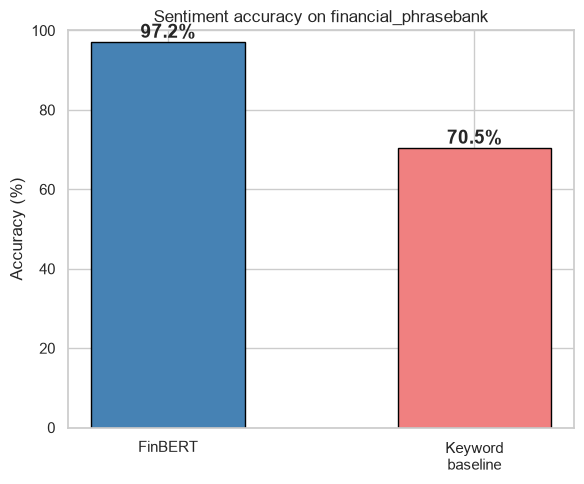

In [12]:
fig, ax = plt.subplots(figsize=(6, 5))
methods = ["FinBERT", "Keyword\nbaseline"]
accs = [fb_metrics["accuracy"] * 100, kw_metrics["accuracy"] * 100]
bars = ax.bar(
    methods, accs, color=["steelblue", "lightcoral"], width=0.5, edgecolor="black"
)
for bar, acc in zip(bars, accs):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{acc:.1f}%",
        ha="center",
        fontsize=14,
        fontweight="bold",
    )
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 100)
ax.set_title("Sentiment accuracy on financial_phrasebank")
plt.tight_layout()
plt.show()


### Confusion matrices — where each method's errors live

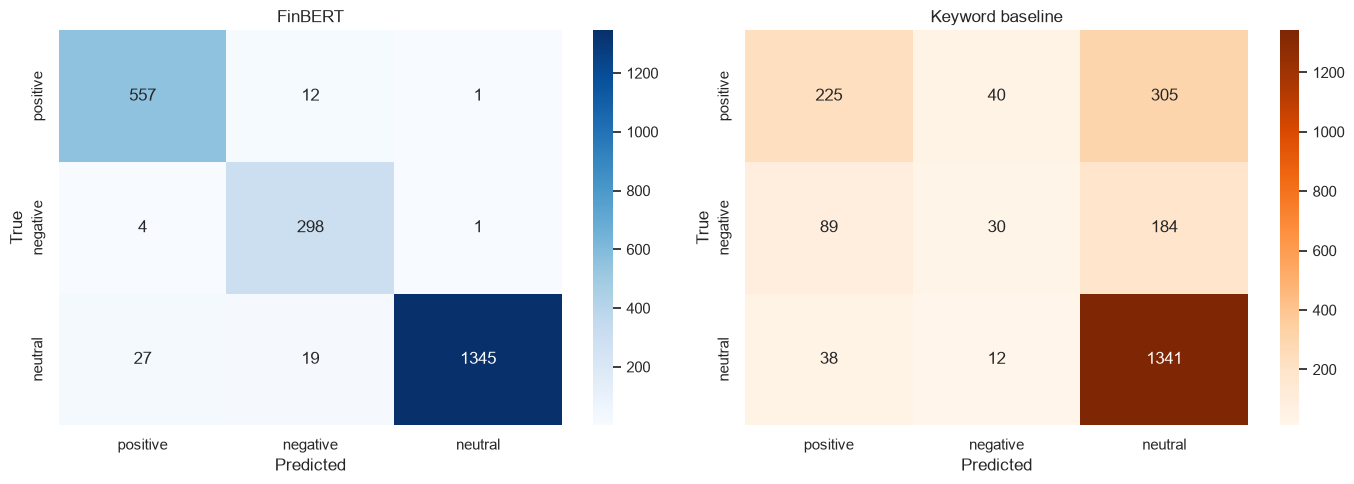

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(fb_cm, annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title("FinBERT")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("True")
sns.heatmap(kw_cm, annot=True, fmt="d", cmap="Oranges", ax=axes[1])
axes[1].set_title("Keyword baseline")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("True")
plt.tight_layout()
plt.show()


**How to read these:** the diagonal is correct predictions; off-diagonal cells are errors. The keyword baseline typically over-predicts **neutral** (many sentences contain no words from the lists, so they default to neutral), and confuses positive/negative on context-dependent sentences. FinBERT's errors concentrate on genuinely ambiguous neutral-vs-directional cases.